# Classification with Nested Cross-Validation
Wine Quality dataset (red and white wines)

The goal is to classify each wine as Low (quality ≤ 5), Medium (= 6) or High (≥ 7).

We use the same nested scheme as in regression (5 outer folds, 3 inner folds with `GridSearchCV`),
but with stratified folds to keep the class proportions, and with the macro F1-score as metric
because the classes are imbalanced.

## 0. Libraries and plot style

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colours for the plots
PLUM, PURPLE, LILAC = "#4A1942", "#7D3C98", "#C39BD3"
PINK, ROSE = "#E0719E", "#F5B7C8"
ORANGE, APRICOT = "#E8743B", "#F6A96B"
CREAM, INK = "#FDF1EC", "#3B2A3F"

PALETTE = [PURPLE, PINK, ORANGE, LILAC, APRICOT, PLUM, ROSE]
CLASS_ORDER = ["Low", "Medium", "High"]
CLASS_COLORS = {"Low": PURPLE, "Medium": PINK, "High": ORANGE}
TYPE_COLORS = {"red": PLUM, "white": APRICOT}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", ROSE, PINK, PURPLE, PLUM])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [PURPLE, LILAC, "#FFFFFF", APRICOT, ORANGE])

sns.set_theme(style="white", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CBB8CF", "axes.labelcolor": INK, "axes.titlecolor": PLUM,
    "axes.titleweight": "semibold", "axes.titlesize": 12, "axes.grid": True,
    "grid.color": "#F1E4EC", "xtick.color": INK, "ytick.color": INK,
    "legend.frameon": False, "text.color": INK,
})

FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("Figure saved ->", FIG_DIR / name)

In [2]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score)

SEED = 42
RES_DIR = Path("../results")
RES_DIR.mkdir(exist_ok=True)

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

## 1. Predictors and target (Low = 0, Medium = 1, High = 2)

In [3]:
FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar",
            "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density",
            "pH", "sulphates", "alcohol"] + ["is_red"]

wine = pd.read_csv("../data/wine_clean.csv")
X = wine[FEATURES].to_numpy()
y = wine["quality_class"].map({c: i for i, c in enumerate(CLASS_ORDER)}).to_numpy()
print("X:", X.shape)
print(pd.Series(y).map(dict(enumerate(CLASS_ORDER))).value_counts().reindex(CLASS_ORDER))

X: (5320, 12)
Low       1988
Medium    2323
High      1009
Name: count, dtype: int64


## 2. Models and hyperparameter grids

In [4]:
def scaled(estimator):
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])

def plain(estimator):
    return Pipeline([("model", estimator)])

MODELS = {
    "Majority baseline":   (plain(DummyClassifier(strategy="most_frequent")), {}),
    "Logistic regression": (scaled(LogisticRegression(max_iter=2000)), {"model__C": [0.01, 0.1, 1, 10]}),
    "KNN":                 (scaled(KNeighborsClassifier()),
                            {"model__n_neighbors": [10, 25, 50], "model__weights": ["uniform", "distance"]}),
    "Decision tree":       (plain(DecisionTreeClassifier(random_state=SEED)),
                            {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [1, 5, 20]}),
    "Random forest":       (plain(RandomForestClassifier(n_estimators=300, random_state=SEED)),
                            {"model__max_features": ["sqrt", 0.5], "model__min_samples_leaf": [1, 5],
                             "model__class_weight": [None, "balanced"]}),
    "Gradient boosting":   (plain(HistGradientBoostingClassifier(random_state=SEED)),
                            {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [15, 31]}),
    "SVM (RBF)":           (scaled(SVC(kernel="rbf", probability=True, random_state=SEED)), {"model__C": [1, 10], "model__gamma": ["scale", 0.3]}),
}

FAMILY_COLORS = {"Majority baseline": "#BDB3C2", "Logistic regression": PURPLE, "KNN": APRICOT,
                 "Decision tree": ROSE, "Random forest": PINK, "Gradient boosting": ORANGE,
                 "SVM (RBF)": "#9C5B8E"}

## 3. Nested cross-validation
We save the outer scores, the chosen hyperparameters, the out-of-fold predictions and, when the
model gives them, the out-of-fold probabilities for the ROC curves.

In [5]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

def short(params):
    return {k.replace("model__", ""): v for k, v in params.items()}

def nested_cv(pipeline, grid, name):
    rows = []
    oof_pred = np.zeros(len(y), dtype=int)
    oof_proba = np.full((len(y), len(CLASS_ORDER)), np.nan)
    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        # inner loop: grid search with the training part only
        search = GridSearchCV(pipeline, grid, scoring="f1_macro", cv=inner_cv, n_jobs=-1)
        search.fit(X_train, y_train)
        best = search.best_estimator_
        # test the best model on the outer test fold
        y_hat = best.predict(X_test)
        oof_pred[test_idx] = y_hat
        if hasattr(best, "predict_proba"):
            oof_proba[test_idx] = best.predict_proba(X_test)
        rows.append({"model": name, "fold": fold,
                     "Accuracy": accuracy_score(y_test, y_hat),
                     "Balanced accuracy": balanced_accuracy_score(y_test, y_hat),
                     "Macro F1": macro_f1(y_test, y_hat),
                     "inner Macro F1": search.best_score_,
                     "best params": short(search.best_params_)})
        print(f"  >fold {fold}: F1={rows[-1]['Macro F1']:.3f}  inner={search.best_score_:.3f}  "
              f"cfg={short(search.best_params_)}")
    return pd.DataFrame(rows), oof_pred, oof_proba

In [6]:
import time

fold_results, oof, oof_proba = [], {}, {}
for name, (pipeline, grid) in MODELS.items():
    start = time.time()
    print(name)
    folds, oof[name], oof_proba[name] = nested_cv(pipeline, grid, name)
    fold_results.append(folds)
    print(f"  Macro F1: {folds['Macro F1'].mean():.3f} ({folds['Macro F1'].std():.3f})   "
          f"[{time.time() - start:.0f}s]\n")

folds_df = pd.concat(fold_results, ignore_index=True)

Majority baseline


  >fold 1: F1=0.203  inner=0.203  cfg={}


  >fold 2: F1=0.202  inner=0.203  cfg={}


  >fold 3: F1=0.202  inner=0.203  cfg={}
  >fold 4: F1=0.203  inner=0.203  cfg={}
  >fold 5: F1=0.203  inner=0.203  cfg={}
  Macro F1: 0.203 (0.000)   [4s]

Logistic regression


  >fold 1: F1=0.553  inner=0.555  cfg={'C': 10}
  >fold 2: F1=0.558  inner=0.564  cfg={'C': 0.1}
  >fold 3: F1=0.564  inner=0.552  cfg={'C': 0.1}
  >fold 4: F1=0.563  inner=0.550  cfg={'C': 10}


  >fold 5: F1=0.548  inner=0.556  cfg={'C': 10}
  Macro F1: 0.557 (0.007)   [1s]

KNN


... (19 outputs left out)

  >fold 2: F1=0.576  inner=0.588  cfg={'C': 10, 'gamma': 'scale'}


  >fold 3: F1=0.570  inner=0.572  cfg={'C': 10, 'gamma': 'scale'}


  >fold 4: F1=0.594  inner=0.576  cfg={'C': 10, 'gamma': 'scale'}


  >fold 5: F1=0.598  inner=0.578  cfg={'C': 10, 'gamma': 'scale'}
  Macro F1: 0.583 (0.013)   [30s]



## 4. Results and confidence intervals
Mean and standard deviation over the 5 outer folds, and 95% bootstrap confidence intervals of the
macro F1 and the accuracy.

In [7]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=42):
    # 95% confidence interval by resampling the out-of-fold predictions
    rng = np.random.default_rng(seed)
    n = len(y_true)
    values = [metric(y_true[idx], y_pred[idx])
              for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(values, [2.5, 97.5])

In [8]:
rows = []
for name in MODELS:
    f = folds_df[folds_df.model == name]
    f1_lo, f1_hi = bootstrap_ci(y, oof[name], macro_f1)
    acc_lo, acc_hi = bootstrap_ci(y, oof[name], accuracy_score)
    proba = oof_proba[name]
    auc = roc_auc_score(y, proba, multi_class="ovr") if not np.isnan(proba).any() else np.nan
    rows.append({"Model": name,
                 "Macro F1 mean": f["Macro F1"].mean(), "Macro F1 std": f["Macro F1"].std(),
                 "F1 95% CI low": f1_lo, "F1 95% CI high": f1_hi,
                 "Accuracy mean": f["Accuracy"].mean(),
                 "Acc 95% CI low": acc_lo, "Acc 95% CI high": acc_hi,
                 "Balanced acc mean": f["Balanced accuracy"].mean(), "ROC-AUC (OvR)": auc})
summary = pd.DataFrame(rows).set_index("Model").sort_values("Macro F1 mean", ascending=False)
summary.to_csv(RES_DIR / "classification_nested_summary.csv")
folds_df.to_csv(RES_DIR / "classification_nested_folds.csv", index=False)
pd.DataFrame(oof).assign(y_true=y).to_csv(RES_DIR / "classification_oof_predictions.csv", index=False)
pd.concat({m: pd.DataFrame(p, columns=CLASS_ORDER) for m, p in oof_proba.items()}, axis=1).to_csv(RES_DIR / "classification_oof_probabilities.csv", index=False)
summary.round(3)

,Macro F1 mean,Macro F1 std,F1 95% CI low,F1 95% CI high,Accuracy mean,Acc 95% CI low,Acc 95% CI high,Balanced acc mean,ROC-AUC (OvR)
Model,,,,,,,,,
Random forest,0.604,0.012,0.592,0.619,0.617,0.604,0.629,0.600,0.790
Gradient boosting,0.592,0.012,0.578,0.606,0.610,0.598,0.623,0.582,0.778
SVM (RBF),0.583,0.013,0.569,0.598,0.611,0.599,0.625,0.571,0.780
KNN,0.579,0.016,0.566,0.594,0.599,0.587,0.613,0.569,0.772
Logistic regression,0.557,0.007,0.543,0.572,0.587,0.574,0.600,0.545,0.758
Decision tree,0.532,0.011,0.517,0.547,0.558,0.545,0.572,0.524,0.717
Majority baseline,0.203,0.000,0.198,0.207,0.437,0.423,0.449,0.333,0.500


Figure saved -> ../results/figures/clf_model_comparison_ci.png


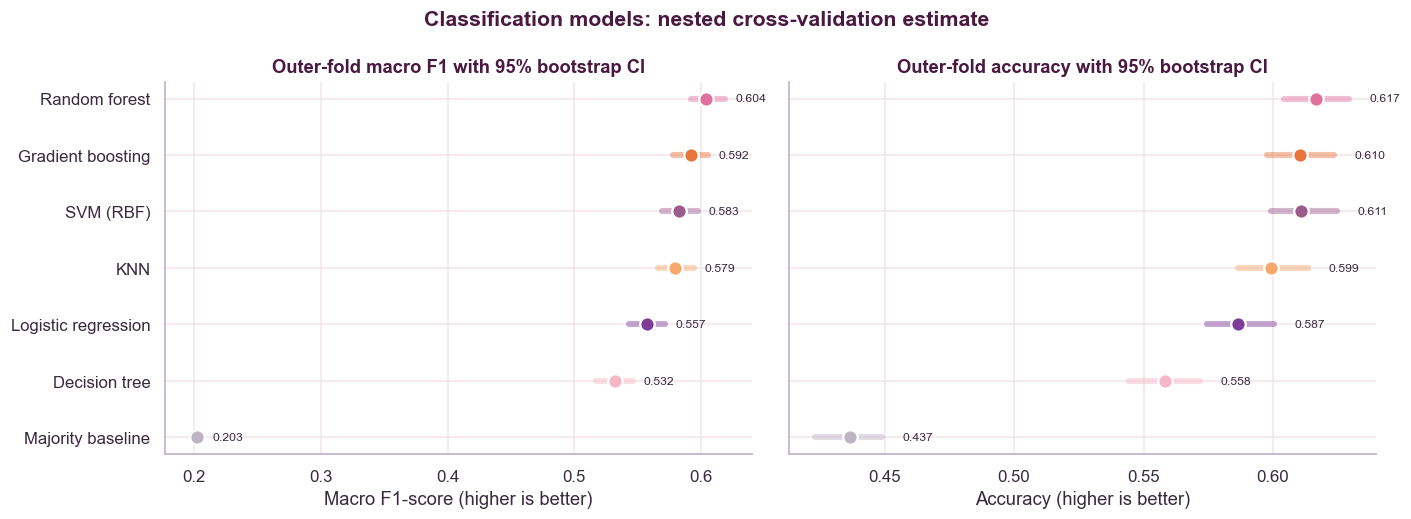

In [9]:
order = summary.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, metric, lo, hi, label in [
        (axes[0], "Macro F1 mean", "F1 95% CI low", "F1 95% CI high", "Macro F1-score"),
        (axes[1], "Accuracy mean", "Acc 95% CI low", "Acc 95% CI high", "Accuracy")]:
    for i, name in enumerate(order):
        ax.plot([summary.loc[name, lo], summary.loc[name, hi]], [i, i], color=FAMILY_COLORS[name],
                lw=4, alpha=0.45, solid_capstyle="round")
        ax.scatter(summary.loc[name, metric], i, s=90, color=FAMILY_COLORS[name],
                   edgecolor="white", linewidth=1.5, zorder=3)
        ax.text(summary.loc[name, hi] + 0.008, i, f"{summary.loc[name, metric]:.3f}",
                fontsize=8, va="center", color=INK)
    ax.set_xlabel(label + " (higher is better)")
axes[0].set_yticks(range(len(order)), order)
axes[0].set_title("Outer-fold macro F1 with 95% bootstrap CI")
axes[1].set_title("Outer-fold accuracy with 95% bootstrap CI")
fig.suptitle("Classification models: nested cross-validation estimate",
             color=PLUM, weight="semibold", fontsize=14)
fig.tight_layout()
save(fig, "clf_model_comparison_ci.png")
plt.show()

Figure saved -> ../results/figures/clf_outer_fold_scores.png


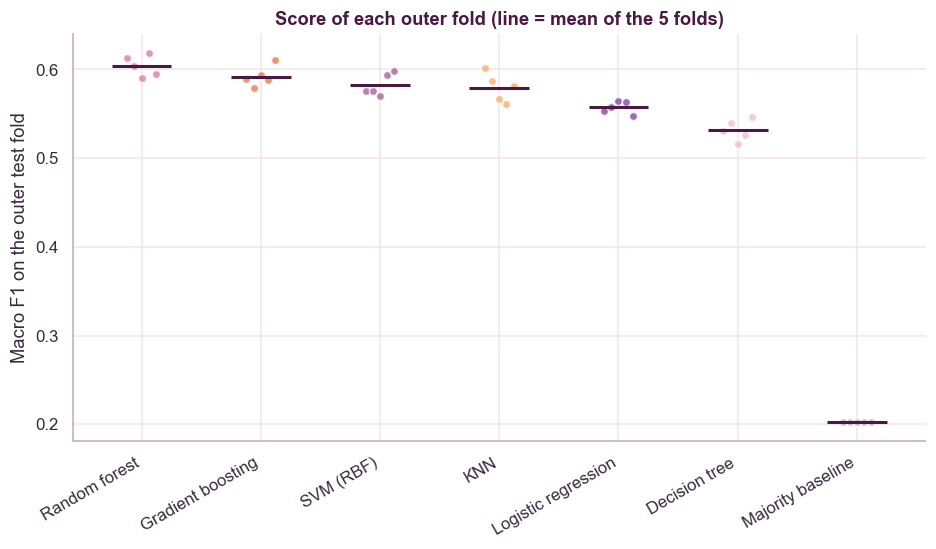

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order = summary.index
for i, name in enumerate(order):
    vals = folds_df.loc[folds_df.model == name, "Macro F1"]
    ax.scatter(np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), vals, s=28,
               color=FAMILY_COLORS[name], alpha=0.75, edgecolor="white")
    ax.hlines(vals.mean(), i - 0.25, i + 0.25, color=PLUM, lw=2)
ax.set_xticks(range(len(order)), order, rotation=30, ha="right")
ax.set_ylabel("Macro F1 on the outer test fold")
ax.set_title("Score of each outer fold (line = mean of the 5 folds)")
save(fig, "clf_outer_fold_scores.png")
plt.show()

## Paired comparison of the best model with the others

Overlapping confidence intervals do not mean that two models are equal. Both models are
evaluated on the same wines, so their errors are correlated. A paired bootstrap resamples the
wines once and computes the metric of the two models on the same resample, which gives a
confidence interval for the difference itself. If the interval does not contain 0, the
difference is significant at the 5% level.

In [11]:
def paired_bootstrap(y_true, pred_a, pred_b, metric, n_boot=2000, seed=42):
    # same resampled wines for both models -> distribution of metric(a) - metric(b)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[b] = metric(y_true[idx], pred_a[idx]) - metric(y_true[idx], pred_b[idx])
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return metric(y_true, pred_a) - metric(y_true, pred_b), lo, hi

best_name = summary.index[0]
rows = []
for other in summary.index[1:]:
    d, lo, hi = paired_bootstrap(y, oof[best_name], oof[other], macro_f1)
    rows.append({"comparison": f"{best_name} - {other}", "difference": d, "CI low": lo, "CI high": hi})
paired = pd.DataFrame(rows).set_index("comparison")
paired.to_csv(RES_DIR / "classification_paired_bootstrap.csv")
paired.round(3)

,difference,CI low,CI high
comparison,,,
Random forest - Gradient boosting,0.014,0.003,0.025
Random forest - SVM (RBF),0.022,0.010,0.035
Random forest - KNN,0.026,0.013,0.038
Random forest - Logistic regression,0.048,0.034,0.063
Random forest - Decision tree,0.073,0.059,0.088
Random forest - Majority baseline,0.403,0.389,0.418


Figure saved -> ../results/figures/clf_paired_bootstrap.png


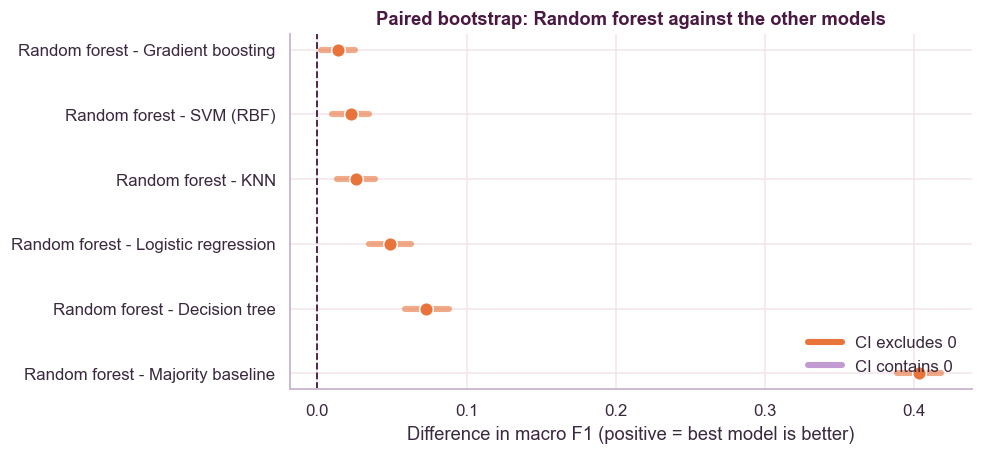

In [12]:
XLABEL = "Difference in macro F1 (positive = best model is better)"
FIGNAME = "clf_paired_bootstrap.png"
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (name, row) in enumerate(paired.iloc[::-1].iterrows()):
    sig = (row["CI low"] > 0) or (row["CI high"] < 0)
    color = ORANGE if sig else LILAC
    ax.plot([row["CI low"], row["CI high"]], [i, i], color=color, lw=4, alpha=0.6, solid_capstyle="round")
    ax.scatter(row["difference"], i, s=80, color=color, edgecolor="white", zorder=3)
ax.axvline(0, color=PLUM, lw=1.2, ls="--")
ax.set_yticks(range(len(paired)), paired.index[::-1])
ax.set_xlabel(XLABEL)
ax.set_title(f"Paired bootstrap: {best_name} against the other models")
handles = [plt.Line2D([], [], color=ORANGE, lw=4, label="CI excludes 0"),
           plt.Line2D([], [], color=LILAC, lw=4, label="CI contains 0")]
ax.legend(handles=handles, loc="lower right")
save(fig, FIGNAME)
plt.show()

## 5. Hyperparameters chosen in each outer fold

In [13]:
params_table = (folds_df[folds_df["best params"].map(len) > 0]
                .assign(params=lambda d: d["best params"].map(lambda p: ", ".join(f"{k}={v}" for k, v in p.items())))
                .pivot(index="model", columns="fold", values="params"))
params_table.columns = [f"Outer fold {c}" for c in params_table.columns]
params_table = params_table.loc[[m for m in summary.index if m in params_table.index]]
params_table.to_csv(RES_DIR / "classification_best_params_per_fold.csv")
params_table

,Outer fold 1,Outer fold 2,Outer fold 3,Outer fold 4,Outer fold 5
model,,,,,
Random forest,"class_weight=balanced, max_features=sqrt, min_...","class_weight=None, max_features=sqrt, min_samp...","class_weight=None, max_features=sqrt, min_samp...","class_weight=None, max_features=sqrt, min_samp...","class_weight=balanced, max_features=sqrt, min_..."
Gradient boosting,"learning_rate=0.1, max_leaf_nodes=31","learning_rate=0.05, max_leaf_nodes=15","learning_rate=0.05, max_leaf_nodes=31","learning_rate=0.1, max_leaf_nodes=15","learning_rate=0.1, max_leaf_nodes=15"
SVM (RBF),"C=1, gamma=0.3","C=10, gamma=scale","C=10, gamma=scale","C=10, gamma=scale","C=10, gamma=scale"
KNN,"n_neighbors=25, weights=distance","n_neighbors=25, weights=distance","n_neighbors=25, weights=distance","n_neighbors=50, weights=distance","n_neighbors=10, weights=distance"
Logistic regression,C=10,C=0.1,C=0.1,C=10,C=10
Decision tree,"max_depth=5, min_samples_leaf=1","max_depth=5, min_samples_leaf=5","max_depth=8, min_samples_leaf=1","max_depth=12, min_samples_leaf=20","max_depth=8, min_samples_leaf=5"


## 6. Best model and final model
Same as in regression: the best model is the one with the highest mean macro F1, and the final
hyperparameters come from a `GridSearchCV` on all the data.

In [14]:
best_name, second_name = summary.index[0], summary.index[1]
b, s = summary.loc[best_name], summary.loc[second_name]
overlap = b["F1 95% CI low"] <= s["F1 95% CI high"]
print(f"Best model : {best_name}  macro F1 {b['Macro F1 mean']:.3f}  "
      f"CI [{b['F1 95% CI low']:.3f}, {b['F1 95% CI high']:.3f}]")
print(f"Second     : {second_name}  macro F1 {s['Macro F1 mean']:.3f}  "
      f"CI [{s['F1 95% CI low']:.3f}, {s['F1 95% CI high']:.3f}]")
print("Confidence intervals overlap:", overlap)

cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipeline, grid = MODELS[best_name]
final_search = GridSearchCV(pipeline, grid, scoring="f1_macro", cv=cv_final, n_jobs=-1).fit(X, y)
final_model = final_search.best_estimator_
print("\nFinal hyperparameters (GridSearchCV on all data):", short(final_search.best_params_))

Best model : Random forest  macro F1 0.604  CI [0.592, 0.619]
Second     : Gradient boosting  macro F1 0.592  CI [0.578, 0.606]
Confidence intervals overlap: True



Final hyperparameters (GridSearchCV on all data): {'class_weight': 'balanced', 'max_features': 'sqrt', 'min_samples_leaf': 5}


## 7. Evaluation of the best model
The confusion matrix, the classification report and the ROC curves are computed with the
out-of-fold predictions.

### 7.1 Confusion matrix

Figure saved -> ../results/figures/clf_confusion_matrix.png


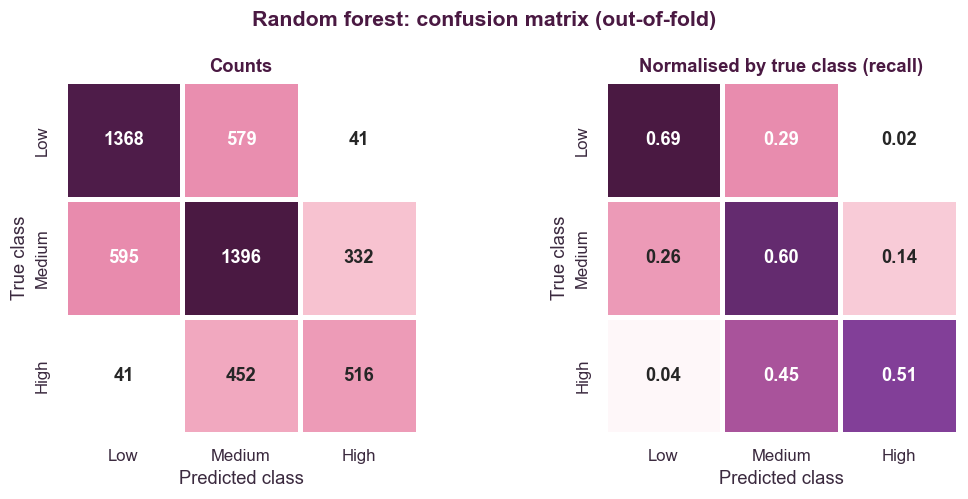

In [15]:
cm = confusion_matrix(y, oof[best_name])
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, mat, fmt, title in [(axes[0], cm, "d", "Counts"), (axes[1], cm_norm, ".2f", "Normalised by true class (recall)")]:
    sns.heatmap(mat, annot=True, fmt=fmt, cmap=CMAP_SEQ, cbar=False, square=True, linewidths=2,
                linecolor="white", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
                annot_kws={"size": 12, "weight": "bold"}, ax=ax)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)
    ax.grid(False)
fig.suptitle(f"{best_name}: confusion matrix (out-of-fold)", color=PLUM, weight="semibold", fontsize=14)
fig.tight_layout()
save(fig, "clf_confusion_matrix.png")
plt.show()

### 7.2 Classification report

              precision    recall  f1-score   support

         Low      0.683     0.688     0.685      1988
      Medium      0.575     0.601     0.588      2323
        High      0.580     0.511     0.544      1009

    accuracy                          0.617      5320
   macro avg      0.613     0.600     0.606      5320
weighted avg      0.616     0.617     0.616      5320



Figure saved -> ../results/figures/clf_classification_report.png


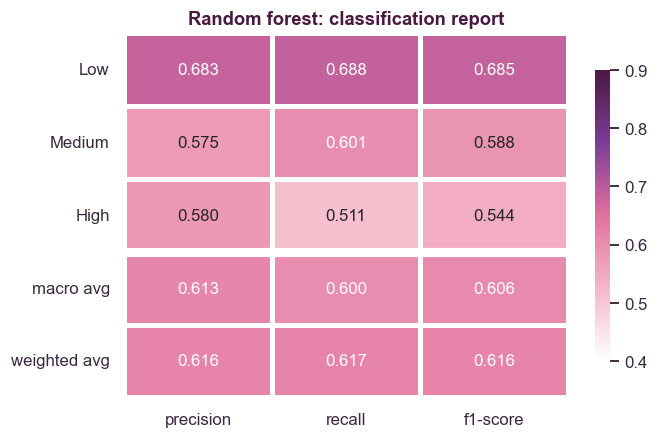

In [16]:
print(classification_report(y, oof[best_name], target_names=CLASS_ORDER, digits=3))
report = pd.DataFrame(classification_report(y, oof[best_name], target_names=CLASS_ORDER,
                                            output_dict=True)).T
report = report.loc[CLASS_ORDER + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score"]]

fig, ax = plt.subplots(figsize=(6.5, 4.3))
sns.heatmap(report, annot=True, fmt=".3f", cmap=CMAP_SEQ, vmin=0.4, vmax=0.9, linewidths=2,
            linecolor="white", cbar_kws={"shrink": 0.8}, annot_kws={"size": 11}, ax=ax)
ax.axhline(3, color="white", lw=6)
ax.set_title(f"{best_name}: classification report")
ax.grid(False)
save(fig, "clf_classification_report.png")
plt.show()

### 7.3 ROC curves (one class vs the rest)

Figure saved -> ../results/figures/clf_roc_curves.png


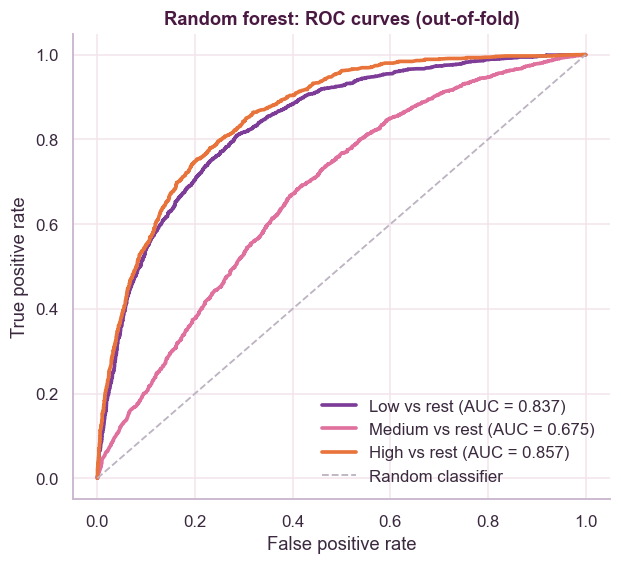

In [17]:
proba = oof_proba[best_name]
y_bin = label_binarize(y, classes=[0, 1, 2])
fig, ax = plt.subplots(figsize=(6.3, 5.5))
for i, c in enumerate(CLASS_ORDER):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    auc = roc_auc_score(y_bin[:, i], proba[:, i])
    ax.plot(fpr, tpr, color=CLASS_COLORS[c], lw=2.4, label=f"{c} vs rest (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#BDB3C2", lw=1.2, label="Random classifier")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"{best_name}: ROC curves (out-of-fold)")
ax.legend(loc="lower right")
save(fig, "clf_roc_curves.png")
plt.show()

### 7.4 Feature importance

,impurity,permutation,permutation std
alcohol,0.204,0.140,0.014
volatile acidity,0.102,0.046,0.009
chlorides,0.084,0.032,0.016
free sulfur dioxide,0.074,0.031,0.012
total sulfur dioxide,0.079,0.029,0.012
density,0.117,0.025,0.020
sulphates,0.073,0.023,0.011
residual sugar,0.068,0.014,0.003
pH,0.067,0.012,0.003
citric acid,0.072,0.012,0.008


Figure saved -> ../results/figures/clf_feature_importance.png


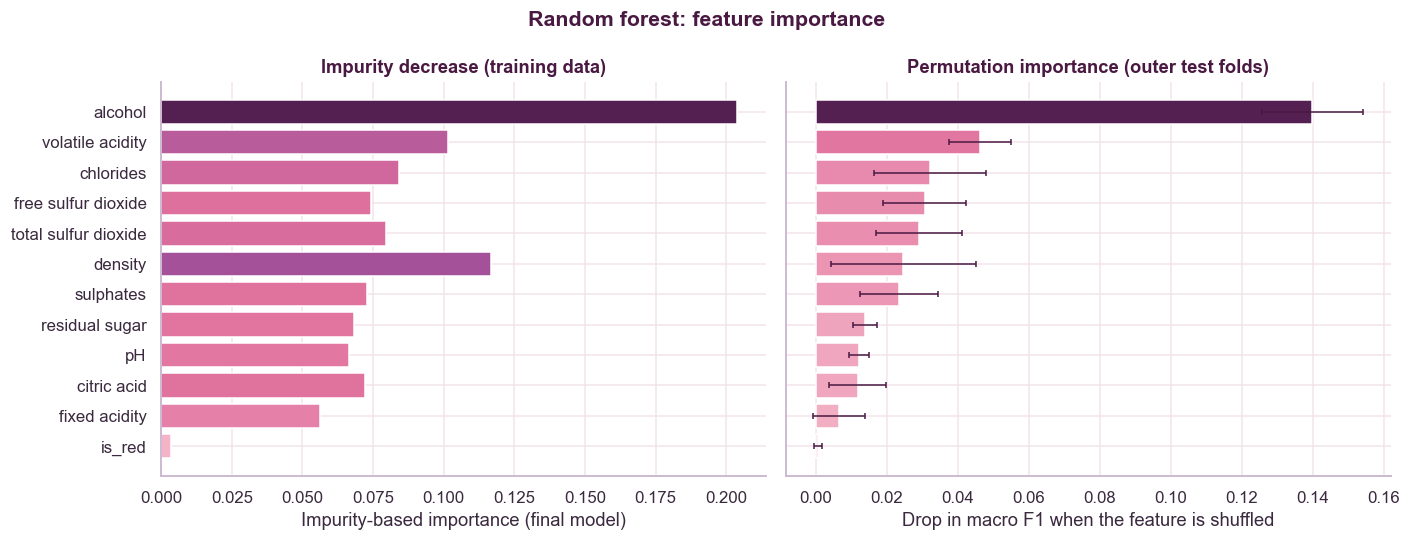

In [18]:
from sklearn.inspection import permutation_importance

SPLIT_ARGS = (X, y)
PERM_SCORING = "f1_macro"
PERM_LABEL = "Drop in macro F1 when the feature is shuffled"
IMP_CSV, IMP_FIG = "classification_feature_importance.csv", "clf_feature_importance.png"
impurity = (pd.Series(final_model.named_steps["model"].feature_importances_, index=FEATURES)
            if hasattr(final_model.named_steps["model"], "feature_importances_") else None)

# permutation importance measured on the outer test folds, with the model of each fold
perm_rows = []
for fold, (train_idx, test_idx) in enumerate(outer_cv.split(*SPLIT_ARGS), start=1):
    params = folds_df[(folds_df.model == best_name) & (folds_df.fold == fold)]["best params"].iloc[0]
    fold_model = clone(MODELS[best_name][0]).set_params(**{f"model__{k}": v for k, v in params.items()})
    fold_model.fit(X[train_idx], y[train_idx])
    r = permutation_importance(fold_model, X[test_idx], y[test_idx], scoring=PERM_SCORING,
                               n_repeats=10, random_state=SEED, n_jobs=-1)
    perm_rows.append(r.importances_mean)
perm = pd.Series(np.mean(perm_rows, axis=0), index=FEATURES)
perm_std = pd.Series(np.std(perm_rows, axis=0), index=FEATURES)

importance = pd.DataFrame({"impurity": impurity, "permutation": perm, "permutation std": perm_std})
importance.round(4).to_csv(RES_DIR / IMP_CSV)
display(importance.sort_values("permutation", ascending=False).round(3))

order = perm.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(order, impurity[order], color=[CMAP_SEQ(0.25 + 0.7 * v / impurity.max()) for v in impurity[order]],
             edgecolor="white")
axes[0].set_xlabel("Impurity-based importance (final model)")
axes[0].set_title("Impurity decrease (training data)")
axes[1].barh(order, perm[order], xerr=perm_std[order], color=[CMAP_SEQ(0.25 + 0.7 * max(v, 0) / perm.max()) for v in perm[order]],
             edgecolor="white", error_kw=dict(ecolor=PLUM, lw=1, capsize=2))
axes[1].set_xlabel(PERM_LABEL)
axes[1].set_title("Permutation importance (outer test folds)")
fig.suptitle(f"{best_name}: feature importance", color=PLUM, weight="semibold", fontsize=14)
fig.tight_layout()
save(fig, IMP_FIG)
plt.show()

## 8. Decision tree
We train a decision tree on all the data with the hyperparameters chosen by `GridSearchCV` and plot
it. We only draw the first three levels so it can be read.

Decision tree hyperparameters (GridSearchCV on all data): {'max_depth': 8, 'min_samples_leaf': 1}


Figure saved -> ../results/figures/clf_decision_tree.png


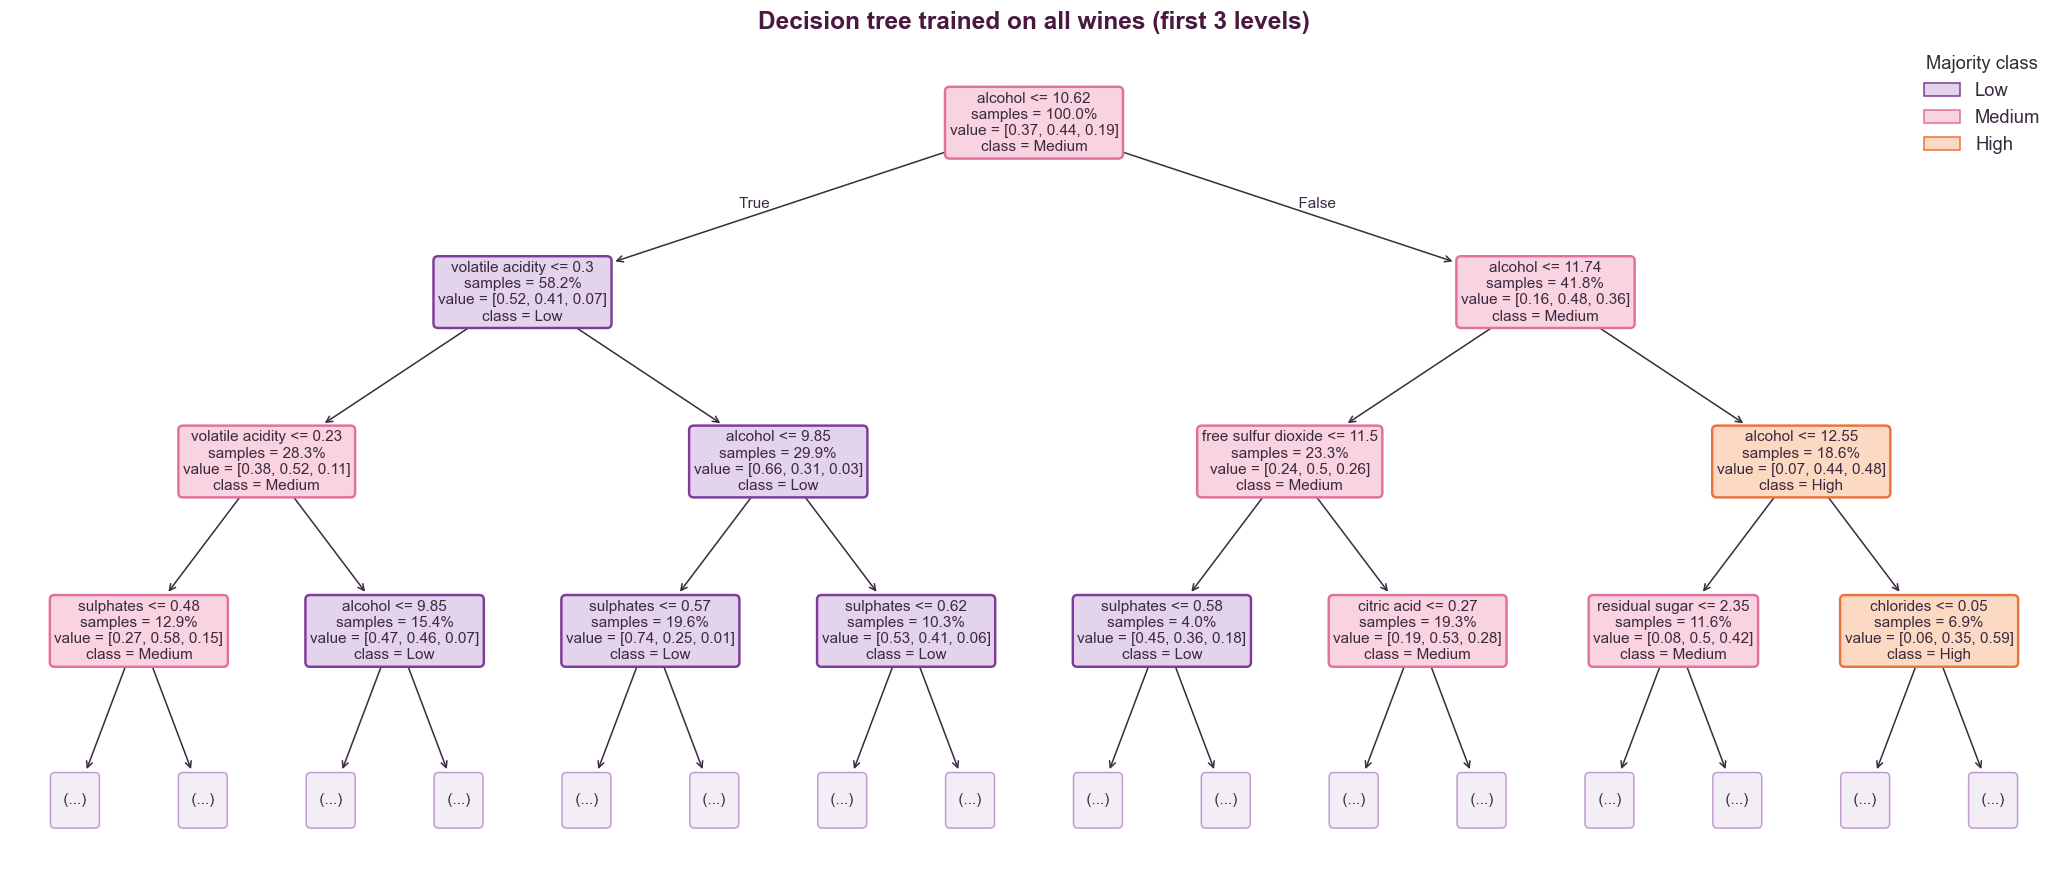

In [19]:
tree_pipeline, tree_grid = MODELS["Decision tree"]
tree_search = GridSearchCV(tree_pipeline, tree_grid, scoring="f1_macro", cv=cv_final, n_jobs=-1).fit(X, y)
tree = tree_search.best_estimator_.named_steps["model"]
print("Decision tree hyperparameters (GridSearchCV on all data):", short(tree_search.best_params_))

TINTS = {"Low": "#E4D3EC", "Medium": "#F9D3DF", "High": "#FBD9C2"}
fig, ax = plt.subplots(figsize=(24, 10))
annotations = plot_tree(tree, max_depth=3, feature_names=FEATURES, class_names=CLASS_ORDER,
                        filled=False, rounded=True, impurity=False, proportion=True,
                        precision=2, fontsize=10, ax=ax)
for a in annotations:
    box = a.get_bbox_patch()
    text = a.get_text()
    if box is None:
        continue
    if "class = " in text:
        cls = text.split("class = ")[-1].strip()
        box.set_facecolor(TINTS[cls])
        box.set_edgecolor(CLASS_COLORS[cls])
        box.set_linewidth(1.6)
    else:
        box.set_facecolor("#F3EDF5")
        box.set_edgecolor(LILAC)
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=TINTS[c], edgecolor=CLASS_COLORS[c]) for c in CLASS_ORDER]
ax.legend(handles, CLASS_ORDER, loc="upper right", fontsize=12, title="Majority class")
ax.set_title("Decision tree trained on all wines (first 3 levels)", fontsize=16)
save(fig, "clf_decision_tree.png")
plt.show()

## Summary

* All the classifiers were tuned inside each outer training set and evaluated on an unseen fold.
* The results are saved in `../results/classification_nested_summary.csv`.
* Most of the errors are between neighbouring classes, especially with Medium.